# Cross-sectional momentum on US stocks, 2016-2025

A standard 12-1 momentum strategy (Jegadeesh and Titman, 1993) built from daily US stock data (`us_stock_daily`, sourced from CRSP) with `quant-research-dataset`:

* **Universe:** ordinary common stocks on NYSE, NYSE American and Nasdaq (`common_only=True`), excluding stocks below the NYSE 20th percentile of market cap.
* **Signal:** cumulative return from month t-12 to t-2, skipping the most recent month to avoid short-term reversal.
* **Portfolios:** value-weighted deciles, rebalanced monthly; long the winners (D10), short the losers (D1).

Returns are before trading costs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import quant_research_dataset as qrd

# Data is read from the Hugging Face Hub by default (run `hf auth login` once).
# To use a local copy instead:  qrd.configure(data_dir="path/to/data")
pd.set_option("display.width", 140)

## Data: 11 years of daily US stock data in one call

In [2]:
daily = qrd.load(
    "us_stock_daily",
    columns=["date", "permno", "ret", "mktcap", "primary_exch", "vwretd"],
    common_only=True,
)
print(
    f"{len(daily):,} rows, {daily.permno.nunique():,} stocks, "
    f"{daily.date.min():%Y-%m-%d} to {daily.date.max():%Y-%m-%d}"
)

10,586,531 rows, 6,635 stocks, 2015-01-02 to 2025-12-31


## Monthly returns and the 12-1 signal

In [3]:
daily["month"] = daily["date"].dt.to_period("M")
daily["logret"] = np.log1p(daily["ret"])
monthly = (
    daily.groupby(["permno", "month"])
    .agg(logret=("logret", "sum"), mktcap=("mktcap", "last"), exch=("primary_exch", "last"))
    .reset_index()
    .sort_values(["permno", "month"])
)
monthly["ret"] = np.expm1(monthly["logret"])
monthly["m"] = monthly["month"].dt.year * 12 + monthly["month"].dt.month  # month number

g = monthly.groupby("permno")
monthly["lag_mktcap"] = g["mktcap"].shift(1)
monthly["lag_exch"] = g["exch"].shift(1)
# Sum of log returns over months t-12..t-2 (11 months), skipping month t-1.
monthly["mom"] = g["logret"].transform(lambda s: s.shift(2).rolling(11, min_periods=11).sum())

# Shifts above count rows; keep only rows where those rows are the right calendar months.
consecutive = (g["m"].shift(1) == monthly["m"] - 1) & (g["m"].shift(12) == monthly["m"] - 12)
panel = monthly[consecutive].copy()
panel[["permno", "month", "ret", "lag_mktcap", "mom"]].head()

,permno,month,ret,lag_mktcap,mom
12,10001,2016-01,0.116779,78262.25,-0.190412
13,10001,2016-02,-0.055287,87401.60,-0.207108
14,10001,2016-03,-0.006359,82569.30,-0.131928
15,10001,2016-04,-0.056315,82067.48,-0.188321
16,10001,2016-05,-0.021919,76737.60,-0.205684


## Size filter (NYSE 20th percentile) and decile sorts

In [4]:
nyse_p20 = (
    panel[panel.lag_exch == "N"].groupby("month")["lag_mktcap"].quantile(0.2).rename("nyse_p20")
)
panel = panel.join(nyse_p20, on="month")
universe = panel[(panel.lag_mktcap >= panel.nyse_p20) & panel.mom.notna() & panel.ret.notna()]
print(
    f"{universe.month.nunique()} months, median {universe.groupby('month').size().median():.0f} stocks per month"
)

port = qrd.quantile_portfolios(
    universe, signal="mom", ret="ret", date="month", n=10, weight="lag_mktcap"
)
port.index = port.index.to_timestamp("M")
market = (
    daily.drop_duplicates("date")
    .groupby("month")["vwretd"]
    .apply(lambda r: np.expm1(np.log1p(r).sum()))
)
market.index = market.index.to_timestamp("M")
port["market"] = market.reindex(port.index)
port.tail()

120 months, median 1813 stocks per month


,1,2,3,4,5,6,7,8,9,10,long_short,market
month,,,,,,,,,,,,
2025-08-31,0.104672,0.060565,0.034932,0.079748,0.034569,0.060606,0.017031,-0.007269,0.002223,-0.012594,-0.117266,0.024044
2025-09-30,0.019091,0.002375,-0.025095,0.058853,0.000088,-0.004725,0.053400,0.005247,0.064112,0.119309,0.100218,0.035572
2025-10-31,0.003177,0.015371,0.038777,0.030625,0.019858,-0.016896,0.022245,0.020353,0.039977,0.052975,0.049798,0.019195
2025-11-30,0.014926,0.008182,0.039846,0.053941,0.011498,0.019004,0.000099,-0.002011,-0.027771,-0.021812,-0.036738,0.001942
2025-12-31,0.029185,0.018108,0.022547,-0.003987,0.008464,0.002972,-0.001265,-0.013867,0.024941,-0.024872,-0.054057,0.001322


## Results

In [5]:
stats = qrd.performance_summary(port[[1, 5, 10, "long_short", "market"]], periods_per_year=12)
stats.style.format(
    {
        "ann_return": "{:.1%}",
        "ann_vol": "{:.1%}",
        "sharpe": "{:.2f}",
        "max_drawdown": "{:.1%}",
        "hit_rate": "{:.0%}",
        "n_periods": "{:.0f}",
    }
)

,ann_return,ann_vol,sharpe,max_drawdown,hit_rate,n_periods
1,8.9%,30.1%,0.43,-55.4%,56%,120
5,13.2%,16.7%,0.83,-31.6%,68%,120
10,20.9%,23.1%,0.94,-29.8%,61%,120
long_short,5.5%,26.1%,0.33,-38.9%,59%,120
market,13.4%,15.4%,0.90,-24.7%,72%,120


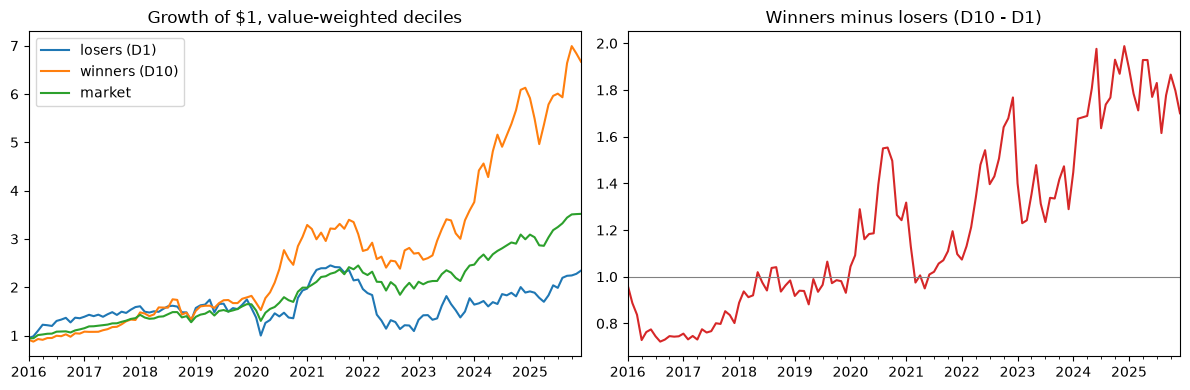

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth = (
    (1 + port[[1, 10, "market"]]).cumprod().rename(columns={1: "losers (D1)", 10: "winners (D10)"})
)
growth.plot(ax=axes[0], title="Growth of $1, value-weighted deciles")
(1 + port["long_short"]).cumprod().plot(
    ax=axes[1], color="C3", title="Winners minus losers (D10 - D1)"
)
axes[1].axhline(1, color="grey", lw=0.8)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig("../docs/img/momentum.png", dpi=120)

In [7]:
yearly = port.groupby(port.index.year)[[10, 1, "long_short", "market"]].apply(
    lambda r: (1 + r).prod() - 1
)
yearly.style.format("{:.1%}")

,10,1,long_short,market
month,,,,
2016,4.0%,35.8%,-25.5%,12.7%
2017,27.1%,17.1%,7.6%,20.7%
2018,0.7%,-18.0%,22.8%,-6.2%
2019,34.4%,33.9%,-5.4%,29.4%
2020,70.0%,10.7%,33.4%,20.7%
2021,1.9%,11.6%,-11.7%,23.0%
2022,-13.0%,-49.3%,61.1%,-19.5%
2023,33.1%,62.2%,-27.1%,24.2%
2024,70.8%,6.6%,54.2%,22.2%


## Takeaways

* Over 2016-2025, past winners (D10) returned about 21% a year against 9% for past losers (D1). The winners-minus-losers spread earned about 5.5% a year, with 26% volatility (Sharpe 0.33) and a 39% maximum drawdown.
* The premium is far from steady. The spread lost heavily in 2016 and 2023, when beaten-down stocks led rebounds, and gained most in 2022 and 2024.
* The whole study (universe screen, monthly returns, size filter, value-weighted decile sorts, performance statistics) takes a few short cells, because data access, cleaning rules and portfolio helpers live in the library.
* Natural next steps: trading costs from bid-ask spreads (`bid`, `ask` are in the dataset), volatility scaling of the long-short leg, and robustness to the size cut-off.